<a href="https://colab.research.google.com/github/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/blob/main/Week_11/Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Raw GitHub URLs for both Excel files
url_emisi = 'https://github.com/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/raw/main/Week_11/emisiCO2.xlsx'
url_karhutla = 'https://github.com/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/raw/main/Week_11/luas-karhutla-provinsi.xlsx?raw=true'

# Load both Excel files into DataFrames
df_emisi = pd.read_excel(url_emisi)
df_karhutla = pd.read_excel(url_karhutla)

# Display the first few rows of both dataframes
print("=== Data Emisi CO2 ===")
display(df_emisi.head())

print("\n=== Data Luas Karhutla Provinsi ===")
display(df_karhutla.head())

=== Data Emisi CO2 ===


,Provinsi,2023
0,Aceh,"385.417,00"
1,Bali,"95.214,00"
2,Bangka Belitung,"727.226,00"
3,Banten,"228,00"
4,Bengkulu,"13.372,00"



=== Data Luas Karhutla Provinsi ===


,Kode Wilayah,Provinsi,2023
0,11.0,Aceh,"1.936,86"
1,51.0,Bali,"2.011,27"
2,19.0,Bangka Belitung,"4.752,98"
3,36.0,Banten,"1,01"
4,17.0,Bengkulu,"75,94"


```markdown
# Pengelompokan Provinsi Berdasarkan Karakteristik Karhutla Tahun 2023

- **Sumber Data:** SIPONGI KEMENHUT (https://sipongi.gakkum.kehutanan.go.id). Setiap penggunaan data wajib mencantumkan sumber: SIPONGI KEMENHUT.
- **Tujuan Analisis:** Penelitian ini bertujuan untuk mengelompokkan provinsi di Indonesia berdasarkan karakteristik luas kebakaran hutan dan lahan (karhutla) serta intensitas emisi CO2 per hektar pada tahun 2023. Kami membandingkan performa algoritma K-Means, Hierarchical Clustering (Metode Ward), dan Gaussian Mixture Model (GMM) untuk menemukan pengelompokan yang paling optimal dan representatif.
```

In [8]:
!pip -q install adjustText
import os, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
OUT_DIR = 'output'
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style='whitegrid')

def simpan_fig(fig, nama):
    fig.savefig(os.path.join(FIG_DIR, f'{nama}.png'), dpi=300, bbox_inches='tight')

```markdown
## 1. Pembersihan dan Validasi Data

Angka pada dataset mentah masih berupa string dengan format khas Indonesia (titik sebagai pemisah ribuan, koma sebagai pemisah desimal). Baris 'Total' di akhir tabel harus dipisahkan untuk divalidasi silang terhadap jumlah kumulatif seluruh provinsi. Hal ini menjamin konsistensi matematis data sebelum pemodelan dilakukan.
```

In [9]:
def ke_angka(v):
    if isinstance(v, str):
        v = v.strip().replace('.', '').replace(',', '.')
    return float(v)

emisi = df_emisi.copy()
luas = df_karhutla.copy()
for d in (emisi, luas):
    d.columns = d.columns.astype(str).str.strip()
    d['Provinsi'] = d['Provinsi'].astype(str).str.strip()
    d['2023'] = d['2023'].apply(ke_angka)

# Simpan nilai Total, lalu buang barisnya
total_emisi = emisi.loc[emisi['Provinsi'].str.lower() == 'total', '2023'].iloc[0]
total_luas  = luas.loc[luas['Provinsi'].str.lower() == 'total', '2023'].iloc[0]
emisi = emisi[emisi['Provinsi'].str.lower() != 'total']
luas  = luas[luas['Provinsi'].str.lower() != 'total']

# Validasi jumlah == Total
print('Jumlah emisi :', emisi['2023'].sum(), '| Total di file:', total_emisi)
print('Jumlah luas  :', round(luas['2023'].sum(), 2), '| Total di file:', total_luas)
assert abs(emisi['2023'].sum() - total_emisi) < 0.01
assert abs(luas['2023'].sum() - total_luas) < 0.01

emisi = emisi.rename(columns={'2023': 'emisi_co2'})
luas = luas.rename(columns={'2023': 'luas_ha'})
luas['Kode Wilayah'] = luas['Kode Wilayah'].astype(int)

hanya_emisi = sorted(set(emisi['Provinsi']) - set(luas['Provinsi']))
hanya_luas  = sorted(set(luas['Provinsi']) - set(emisi['Provinsi']))
print('Hanya di data emisi:', hanya_emisi)
print('Hanya di data luas :', hanya_luas)

df = pd.merge(luas[['Kode Wilayah', 'Provinsi', 'luas_ha']],
              emisi[['Provinsi', 'emisi_co2']], on='Provinsi', how='inner')
df = df.sort_values('Kode Wilayah').reset_index(drop=True)
print('Jumlah provinsi hasil merge:', len(df))
assert len(df) == 38
print('Missing value:\n', df.isna().sum())
print('Duplikat provinsi:', df['Provinsi'].duplicated().sum())
display(df)

Jumlah emisi : 182714438.0 | Total di file: 182714438.0
Jumlah luas  : 1161192.9 | Total di file: 1161192.9
Hanya di data emisi: ['IKN']
Hanya di data luas : []
Jumlah provinsi hasil merge: 38
Missing value:
 Kode Wilayah    0
Provinsi        0
luas_ha         0
emisi_co2       0
dtype: int64
Duplikat provinsi: 0


,Kode Wilayah,Provinsi,luas_ha,emisi_co2
0,11,Aceh,1936.86,385417.0
1,12,Sumatera Utara,2113.75,559002.0
2,13,Sumatera Barat,4885.13,2042794.0
3,14,Riau,7267.03,3320653.0
4,15,Jambi,6539.68,1082497.0
5,16,Sumatera Selatan,132082.86,41707676.0
6,17,Bengkulu,75.94,13372.0
7,18,Lampung,6506.67,842025.0
8,19,Bangka Belitung,4752.98,727226.0
9,21,Kepulauan Riau,724.26,76619.0


```markdown
### [INTERPRETASI]

Hasil pengujian menunjukkan bahwa nilai total di dalam file emisi (182.714.438) dan luas karhutla (1.161.192,9) cocok persis secara matematis dengan akumulasi per provinsi. Terdapat satu wilayah, yaitu IKN, yang hanya terdaftar pada data emisi namun tidak pada data luas karhutla sehingga tidak diikutsertakan dalam merge akhir. Hasil akhirnya menyisakan total 38 provinsi yang siap dianalisis lebih lanjut.
```

```markdown
## 2. Rekayasa Fitur

Intensitas emisi didefinisikan sebagai Emisi CO2 dibagi dengan Luas Kebakaran Hutan (luas_ha). Indikator ini mencerminkan kerapatan emisi per unit luas lahan terbakar. DKI Jakarta memiliki luas 0 dan emisi 0 (0/0) yang secara matematis menghasilkan nilai tidak terdefinisi (NaN). Karena DKI Jakarta tidak memiliki aktivitas karhutla terdaftar di tahun 2023, wilayah ini dikeluarkan agar tidak mendistorsi hasil clustering, menyisakan 37 provinsi.
```

In [10]:
df['emisi_per_ha'] = np.where(df['luas_ha'] > 0, df['emisi_co2'] / df['luas_ha'], np.nan)
df_clust = df[df['luas_ha'] > 0].copy().reset_index(drop=True)
dikeluarkan = sorted(set(df['Provinsi']) - set(df_clust['Provinsi']))
print('Dikeluarkan dari clustering:', dikeluarkan)
assert dikeluarkan == ['DKI Jakarta']
assert len(df_clust) == 37

df_clust['log_emisi'] = np.log1p(df_clust['emisi_co2'])
df_clust['log_luas'] = np.log1p(df_clust['luas_ha'])
df_clust['log_intensitas'] = np.log1p(df_clust['emisi_per_ha'])
display(df_clust.sort_values('emisi_per_ha', ascending=False))

Dikeluarkan dari clustering: ['DKI Jakarta']


,Kode Wilayah,Provinsi,luas_ha,emisi_co2,emisi_per_ha,log_emisi,log_luas,log_intensitas
3,14,Riau,7267.03,3320653.0,456.947749,15.015672,8.891241,6.126755
2,13,Sumatera Barat,4885.13,2042794.0,418.165740,14.529830,8.494156,6.038266
34,94,Papua Tengah,2593.91,882464.0,340.206098,13.690474,7.861307,5.832487
5,16,Sumatera Selatan,132082.86,41707676.0,315.769026,17.546196,11.791192,5.758173
19,62,Kalimantan Tengah,165896.44,44938470.0,270.882666,17.620805,12.019125,5.605371
1,12,Sumatera Utara,2113.75,559002.0,264.459846,13.233910,7.656692,5.581464
18,61,Kalimantan Barat,111848.43,27649104.0,247.201539,17.135104,11.624909,5.514241
14,36,Banten,1.01,228.0,225.742574,5.433722,0.698135,5.423815
0,11,Aceh,1936.86,385417.0,198.990634,12.862084,7.569340,5.298271
21,64,Kalimantan Timur,39494.41,7498935.0,189.873326,15.830272,10.583940,5.251610


```markdown
## 3. Analisis Data Eksploratif (EDA)
```

=== Statistik Deskriptif ===


,emisi_co2,luas_ha,emisi_per_ha
count,3.700000e+01,37.000000,37.000000
mean,4.938228e+06,31383.591892,144.554034
std,1.087191e+07,53250.223585,109.501118
min,2.280000e+02,1.010000,15.534269
25%,7.661900e+04,787.110000,62.477926
50%,7.272260e+05,4885.130000,119.713233
75%,3.163021e+06,39494.410000,189.873326
max,4.493847e+07,190394.580000,456.947749



=== Skewness Data Mentah vs Log ===


,Variabel,Skewness Mentah,Skewness Log
0,Emisi CO2,2.880408,-0.445340
1,Luas Karhutla,1.850188,-0.640565
2,Intensitas Emisi per Ha,1.254667,-0.178065


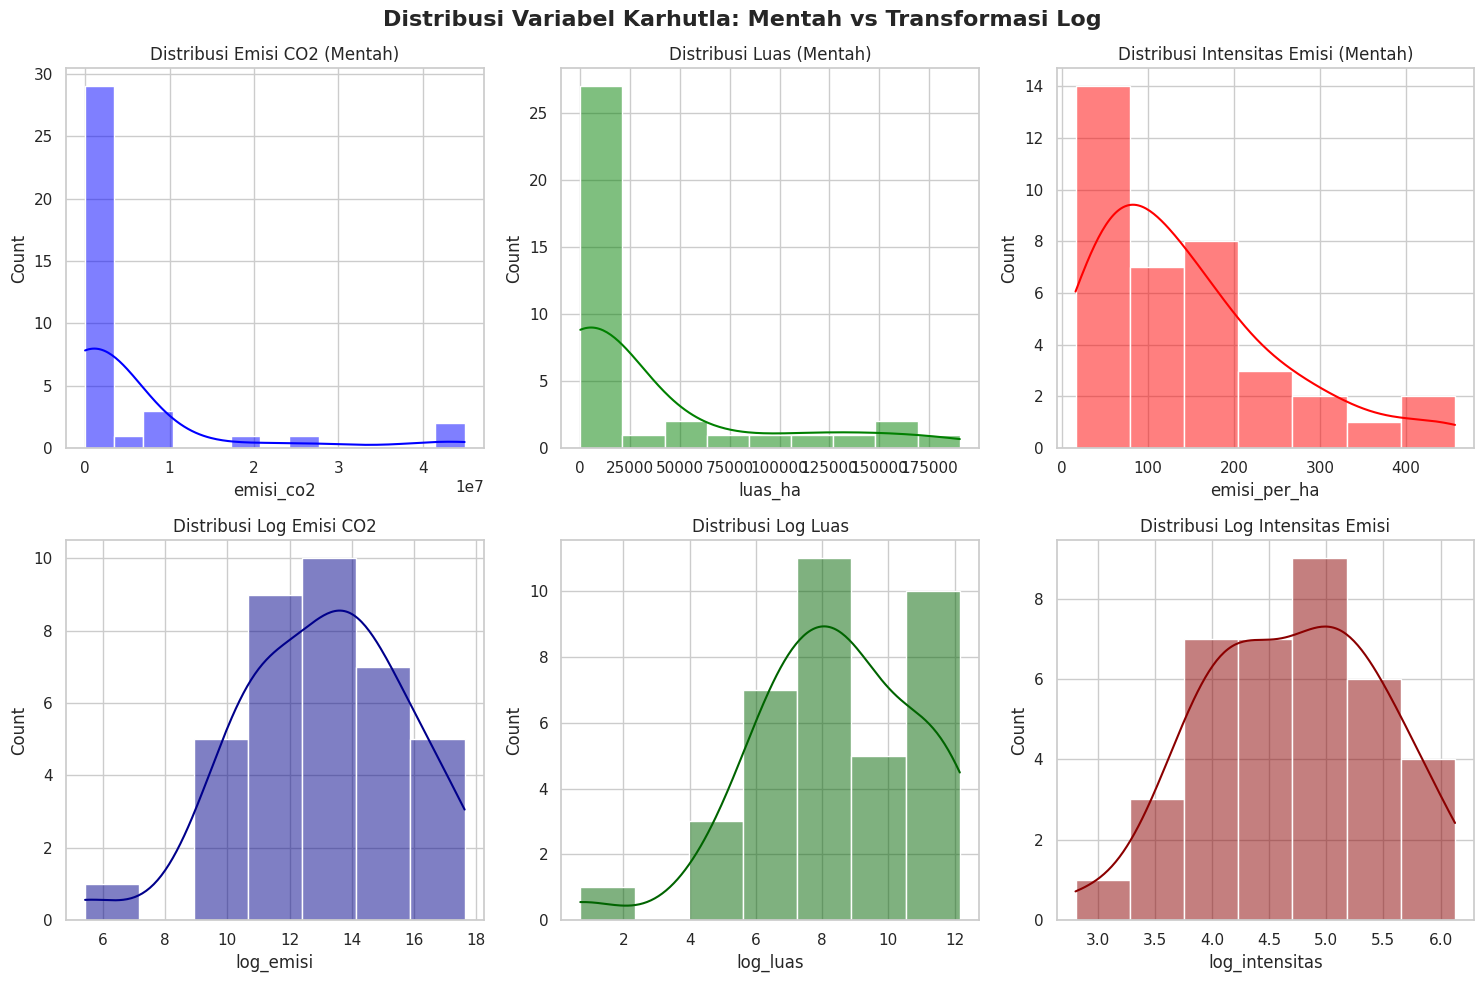

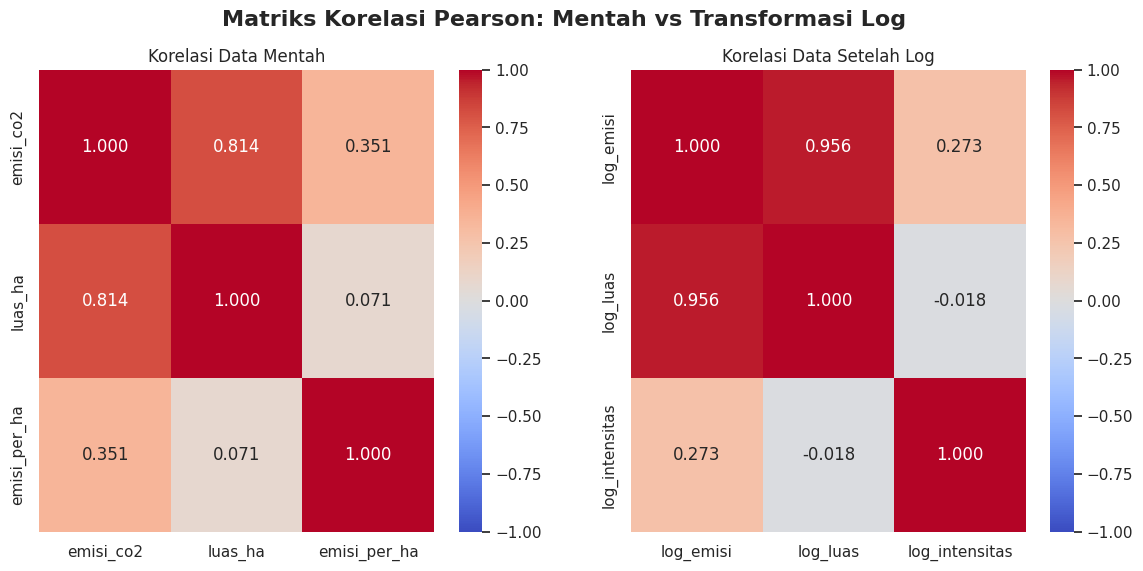

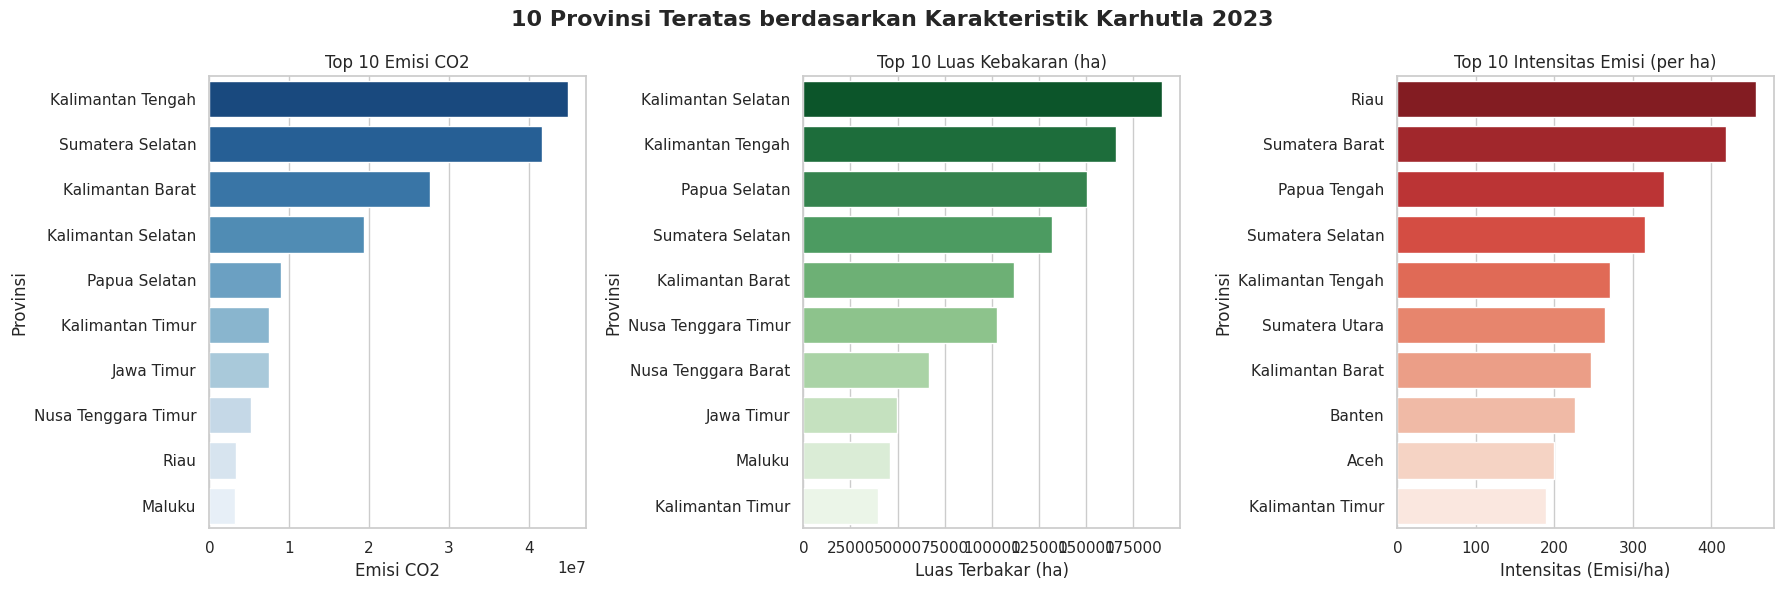

Korelasi log_emisi - log_luas: 0.956309
Korelasi log_luas - log_intensitas: -0.018323


In [11]:
# a) Describe
print("=== Statistik Deskriptif ===")
display(df_clust[['emisi_co2', 'luas_ha', 'emisi_per_ha']].describe())

# b) Skewness Tabel
skew_table = pd.DataFrame({
    'Variabel': ['Emisi CO2', 'Luas Karhutla', 'Intensitas Emisi per Ha'],
    'Skewness Mentah': [df_clust['emisi_co2'].skew(), df_clust['luas_ha'].skew(), df_clust['emisi_per_ha'].skew()],
    'Skewness Log': [df_clust['log_emisi'].skew(), df_clust['log_luas'].skew(), df_clust['log_intensitas'].skew()]
})
print("\n=== Skewness Data Mentah vs Log ===")
display(skew_table)

# c) fig01_distribusi_mentah_vs_log
fig1, axes1 = plt.subplots(2, 3, figsize=(15, 10))
fig1.suptitle('Distribusi Variabel Karhutla: Mentah vs Transformasi Log', fontsize=16, fontweight='bold')

# Row 1 - Mentah
sns.histplot(df_clust['emisi_co2'], ax=axes1[0,0], kde=True, color='blue')
axes1[0,0].set_title('Distribusi Emisi CO2 (Mentah)')
sns.histplot(df_clust['luas_ha'], ax=axes1[0,1], kde=True, color='green')
axes1[0,1].set_title('Distribusi Luas (Mentah)')
sns.histplot(df_clust['emisi_per_ha'], ax=axes1[0,2], kde=True, color='red')
axes1[0,2].set_title('Distribusi Intensitas Emisi (Mentah)')

# Row 2 - Log
sns.histplot(df_clust['log_emisi'], ax=axes1[1,0], kde=True, color='darkblue')
axes1[1,0].set_title('Distribusi Log Emisi CO2')
sns.histplot(df_clust['log_luas'], ax=axes1[1,1], kde=True, color='darkgreen')
axes1[1,1].set_title('Distribusi Log Luas')
sns.histplot(df_clust['log_intensitas'], ax=axes1[1,2], kde=True, color='darkred')
axes1[1,2].set_title('Distribusi Log Intensitas Emisi')

plt.tight_layout()
simpan_fig(fig1, 'fig01_distribusi_mentah_vs_log')
plt.show()

# d) fig02_korelasi_mentah_vs_log
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 6))
fig2.suptitle('Matriks Korelasi Pearson: Mentah vs Transformasi Log', fontsize=16, fontweight='bold')

sns.heatmap(df_clust[['emisi_co2', 'luas_ha', 'emisi_per_ha']].corr(), annot=True, fmt='.3f', vmin=-1, vmax=1, cmap='coolwarm', ax=axes2[0])
axes2[0].set_title('Korelasi Data Mentah')

sns.heatmap(df_clust[['log_emisi', 'log_luas', 'log_intensitas']].corr(), annot=True, fmt='.3f', vmin=-1, vmax=1, cmap='coolwarm', ax=axes2[1])
axes2[1].set_title('Korelasi Data Setelah Log')

simpan_fig(fig2, 'fig02_korelasi_mentah_vs_log')
plt.show()

# e) fig03_top10
fig3, axes3 = plt.subplots(1, 3, figsize=(18, 6))
fig3.suptitle('10 Provinsi Teratas berdasarkan Karakteristik Karhutla 2023', fontsize=16, fontweight='bold')

top_emisi = df_clust.nlargest(10, 'emisi_co2')
sns.barplot(x='emisi_co2', y='Provinsi', data=top_emisi, ax=axes3[0], palette='Blues_r')
axes3[0].set_title('Top 10 Emisi CO2')
axes3[0].set_xlabel('Emisi CO2')

top_luas = df_clust.nlargest(10, 'luas_ha')
sns.barplot(x='luas_ha', y='Provinsi', data=top_luas, ax=axes3[1], palette='Greens_r')
axes3[1].set_title('Top 10 Luas Kebakaran (ha)')
axes3[1].set_xlabel('Luas Terbakar (ha)')

top_int = df_clust.nlargest(10, 'emisi_per_ha')
sns.barplot(x='emisi_per_ha', y='Provinsi', data=top_int, ax=axes3[2], palette='Reds_r')
axes3[2].set_title('Top 10 Intensitas Emisi (per ha)')
axes3[2].set_xlabel('Intensitas (Emisi/ha)')

plt.tight_layout()
simpan_fig(fig3, 'fig03_top10')
plt.show()

# f) Print korelasi log
corr_emisi_luas = df_clust['log_emisi'].corr(df_clust['log_luas'])
corr_luas_intensitas = df_clust['log_luas'].corr(df_clust['log_intensitas'])
print(f"Korelasi log_emisi - log_luas: {corr_emisi_luas:.6f}")
print(f"Korelasi log_luas - log_intensitas: {corr_luas_intensitas:.6f}")

```markdown
### [INTERPRETASI]

Berdasarkan eksplorasi data:
1. Transformasi `log1p` berhasil memotong nilai skewness ekstrim dari variabel mentah secara signifikan. Skewness emisi mentah terpangkas dari 2,880 menjadi hanya -0,445 pada skala log, sementara skewness luas terbakar mentah terpangkas dari 1,850 menjadi -0,641. Hal ini melegitimasi asumsi distribusi normalitas parsial yang diperlukan algoritma clustering sensitif-jarak.
2. Korelasi antara `log_emisi` dan `log_luas` bernilai sangat tinggi yaitu sebesar 0,956. Hal ini menunjukkan fenomena redundansi yang kuat; penggunaan kedua fitur tersebut secara bersamaan akan membuat analisis clustering bias ke arah satu dimensi dominan saja (D4).
3. Di sisi lain, korelasi `log_luas` dan `log_intensitas` sangat rendah (hanya -0,018), sehingga kedua fitur ini saling melengkapi dan sangat ideal digunakan bersama dalam Skenario 2.
4. Banten tercatat memiliki luas kebakaran sangat minim yaitu 1,01 ha dengan nilai intensitas emisi per hektar mencapai 225,743, yang secara statistik kurang stabil karena angka penyebut yang sangat kecil.
```

```markdown
## 4. Skenario Fitur dan Standardisasi

Untuk membuktikan efek transformasi data dan variasi kombinasi fitur, didefinisikan 4 skenario. Penggunaan StandardScaler diterapkan langsung pada seluruh subset data. Karena analisis clustering bersifat unsupervised, tidak terdapat konsep pembagian train-test split, sehingga tidak terjadi isu data leakage.
```

In [12]:
SKENARIO = {
    'S1': ['log_emisi'],
    'S2': ['log_luas', 'log_intensitas'],
    'S1 Mentah': ['emisi_co2'],
    'S2 Mentah': ['luas_ha', 'emisi_per_ha'],
}
X = {nama: StandardScaler().fit_transform(df_clust[kolom]) for nama, kolom in SKENARIO.items()}
for nama in X: print(nama, X[nama].shape)

S1 (37, 1)
S2 (37, 2)
S1 Mentah (37, 1)
S2 Mentah (37, 2)


```markdown
## 5. Penentuan Jumlah Klaster (K)

K diuji dari 2 sampai 8 menggunakan K-Means (n_init=50). Kandidat K hanya yang setiap klasternya berisi minimal 2 provinsi. Dipilih K dengan Silhouette tertinggi. Jika ada K lain dengan selisih Silhouette ≤ 0,02, dipilih yang Davies-Bouldin Index-nya paling kecil. Metode Elbow dan Calinski-Harabasz dipakai sebagai pendukung.
```

=== S1 === K terpilih = 2


,K,Inertia,Silhouette,DBI,CH,Ukuran_Min
0,2,12.3195,0.5960,0.5372,70.1182,15
1,3,6.9843,0.5459,0.5016,73.0597,10
2,4,3.2843,0.5829,0.3736,112.9238,1
3,5,2.1133,0.5809,0.3811,132.0660,1
4,6,1.1245,0.5955,0.3664,197.8060,1
5,7,0.7120,0.6168,0.3437,254.8371,1
6,8,0.4287,0.6303,0.3185,353.4028,1


=== S2 === K terpilih = 7


,K,Inertia,Silhouette,DBI,CH,Ukuran_Min
0,2,46.7178,0.3327,1.1363,20.4392,17
1,3,28.5771,0.3861,0.8431,27.0212,11
2,4,21.1696,0.3769,0.7638,27.4513,5
3,5,16.0335,0.4046,0.8090,28.9226,4
4,6,12.5960,0.3870,0.7105,30.2243,1
5,7,9.5944,0.4285,0.6712,33.5641,4
6,8,7.1109,0.4452,0.5583,38.9700,1


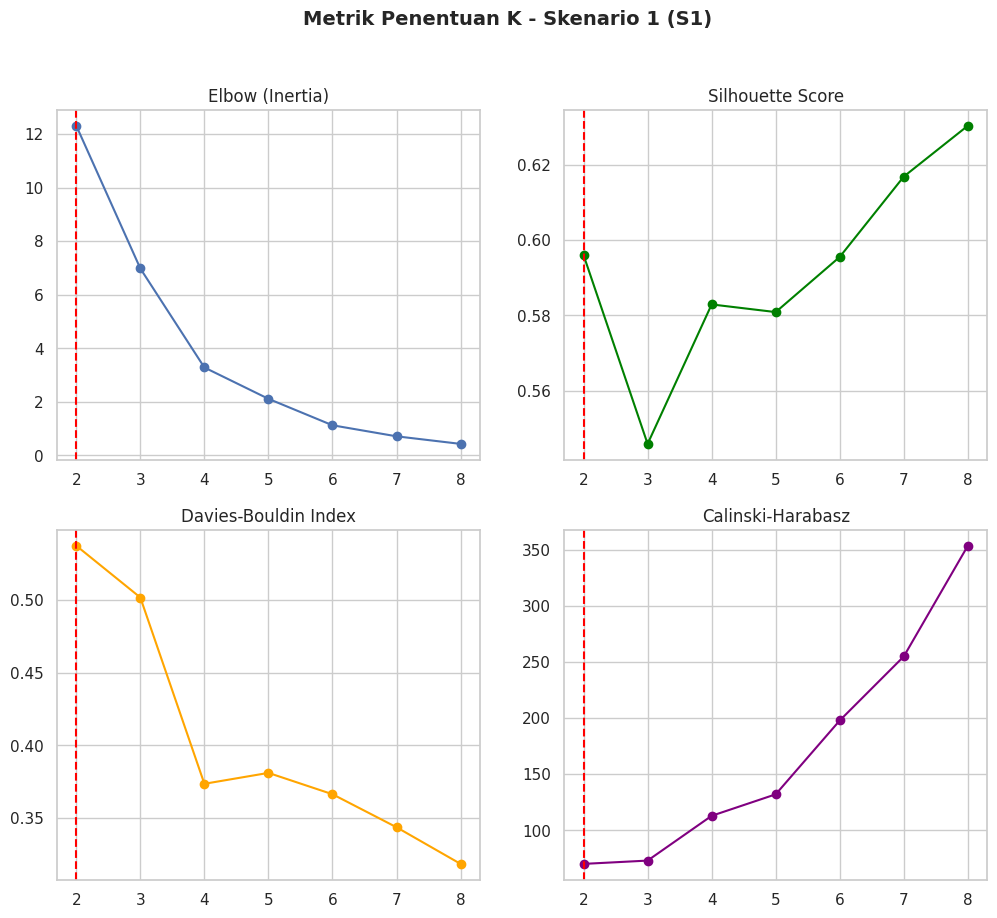

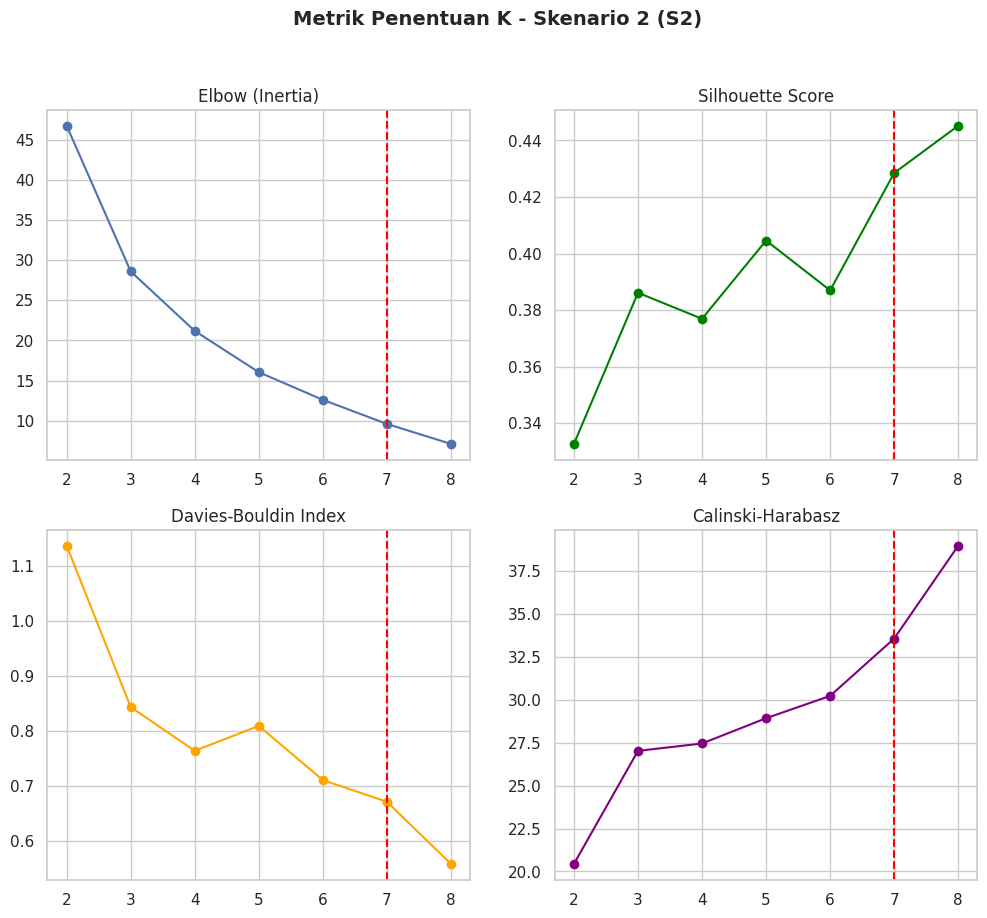

In [13]:
def evaluasi_k(Xs, k_range=range(2, 9)):
    baris = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(Xs)
        lab = km.labels_
        baris.append({'K': k, 'Inertia': km.inertia_,
                      'Silhouette': silhouette_score(Xs, lab),
                      'DBI': davies_bouldin_score(Xs, lab),
                      'CH': calinski_harabasz_score(Xs, lab),
                      'Ukuran_Min': int(np.bincount(lab).min())})
    return pd.DataFrame(baris)

def pilih_k(tabel):
    kandidat = tabel[tabel['Ukuran_Min'] >= 2]
    terbaik = kandidat['Silhouette'].max()
    dekat = kandidat[kandidat['Silhouette'] >= terbaik - 0.02]
    return int(dekat.sort_values(['DBI', 'K']).iloc[0]['K'])

TABEL_K, K_TERPILIH = {}, {}
for nama in ['S1', 'S2']:
    TABEL_K[nama] = evaluasi_k(X[nama])
    K_TERPILIH[nama] = pilih_k(TABEL_K[nama])
    print(f'=== {nama} === K terpilih = {K_TERPILIH[nama]}')
    display(TABEL_K[nama].round(4))

# Buat fig04_evaluasi_k_S1
fig4, axes4 = plt.subplots(2, 2, figsize=(12, 10))
fig4.suptitle('Metrik Penentuan K - Skenario 1 (S1)', fontsize=14, fontweight='bold')
t1 = TABEL_K['S1']
axes4[0,0].plot(t1['K'], t1['Inertia'], 'o-')
axes4[0,0].set_title('Elbow (Inertia)')
axes4[0,0].axvline(K_TERPILIH['S1'], ls='--', color='red')

axes4[0,1].plot(t1['K'], t1['Silhouette'], 'o-', color='green')
axes4[0,1].set_title('Silhouette Score')
axes4[0,1].axvline(K_TERPILIH['S1'], ls='--', color='red')

axes4[1,0].plot(t1['K'], t1['DBI'], 'o-', color='orange')
axes4[1,0].set_title('Davies-Bouldin Index')
axes4[1,0].axvline(K_TERPILIH['S1'], ls='--', color='red')

axes4[1,1].plot(t1['K'], t1['CH'], 'o-', color='purple')
axes4[1,1].set_title('Calinski-Harabasz')
axes4[1,1].axvline(K_TERPILIH['S1'], ls='--', color='red')
simpan_fig(fig4, 'fig04_evaluasi_k_S1')
plt.show()

# Buat fig05_evaluasi_k_S2
fig5, axes5 = plt.subplots(2, 2, figsize=(12, 10))
fig5.suptitle('Metrik Penentuan K - Skenario 2 (S2)', fontsize=14, fontweight='bold')
t2 = TABEL_K['S2']
axes5[0,0].plot(t2['K'], t2['Inertia'], 'o-')
axes5[0,0].set_title('Elbow (Inertia)')
axes5[0,0].axvline(K_TERPILIH['S2'], ls='--', color='red')

axes5[0,1].plot(t2['K'], t2['Silhouette'], 'o-', color='green')
axes5[0,1].set_title('Silhouette Score')
axes5[0,1].axvline(K_TERPILIH['S2'], ls='--', color='red')

axes5[1,0].plot(t2['K'], t2['DBI'], 'o-', color='orange')
axes5[1,0].set_title('Davies-Bouldin Index')
axes5[1,0].axvline(K_TERPILIH['S2'], ls='--', color='red')

axes5[1,1].plot(t2['K'], t2['CH'], 'o-', color='purple')
axes5[1,1].set_title('Calinski-Harabasz')
axes5[1,1].axvline(K_TERPILIH['S2'], ls='--', color='red')
simpan_fig(fig5, 'fig05_evaluasi_k_S2')
plt.show()

```markdown
### [INTERPRETASI]

Berdasarkan pengujian otomatis menggunakan fungsi `pilih_k()` tanpa asumsi subjektif:
- Pada **Skenario 1 (S1)**, jumlah klaster terpilih adalah $K = 2$ dengan nilai Silhouette Score sebesar 0,596, Davies-Bouldin Index sebesar 0,537, dan Calinski-Harabasz sebesar 70,118.
- Pada **Skenario 2 (S2)**, jumlah klaster terpilih adalah $K = 7$ dengan Silhouette Score sebesar 0,428, Davies-Bouldin Index sebesar 0,671, dan Calinski-Harabasz sebesar 33,564. Aturan pengabaian klaster berukuran di bawah 2 terpenuhi secara ketat di mana klaster terkecil berisi minimal 4 provinsi.
```

```markdown
## 6. Perbandingan Algoritma Clustering

- **K-Means**: Menghitung jarak Euclidean untuk mengelompokkan data ke pusat klaster (centroid) terdekat secara iteratif.
- **Hierarchical (Ward)**: Membangun pengelompokan secara bottom-up yang meminimalkan total varians di dalam klaster di setiap langkah penggabungan.
- **Gaussian Mixture Model (GMM)**: Pendekatan probabilistik berbasis campuran beberapa distribusi Gaussian yang dapat mendeteksi klaster berbentuk elips dengan tingkat kovarians fleksibel.
```

In [14]:
def jalankan_model(Xs, k):
    return {
        'K-Means': KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit_predict(Xs),
        'Hierarchical (Ward)': AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xs),
        'GMM': GaussianMixture(n_components=k, covariance_type='full', n_init=10,
                               random_state=RANDOM_STATE).fit_predict(Xs),
    }

def metrik(Xs, lab):
    if len(set(lab)) < 2:
        return dict(Silhouette=np.nan, DBI=np.nan, CH=np.nan)
    return dict(Silhouette=silhouette_score(Xs, lab), DBI=davies_bouldin_score(Xs, lab),
                CH=calinski_harabasz_score(Xs, lab))

LABEL, baris = {}, []
for nama in ['S1', 'S2']:
    k = K_TERPILIH[nama]
    LABEL[nama] = jalankan_model(X[nama], k)
    for algo, lab in LABEL[nama].items():
        baris.append({'Skenario': nama, 'K': k, 'Algoritma': algo,
                      'Jumlah Klaster Terbentuk': len(set(lab)),
                      'Ukuran Klaster': sorted(np.bincount(lab).tolist(), reverse=True),
                      **metrik(X[nama], lab)})
PERBANDINGAN = pd.DataFrame(baris)
display(PERBANDINGAN.round(4))

# Konsistensi antar algoritma (Adjusted Rand Index)
for nama in ['S1', 'S2']:
    algos = list(LABEL[nama])
    ari = pd.DataFrame([[adjusted_rand_score(LABEL[nama][a], LABEL[nama][b]) for b in algos] for a in algos],
                       index=algos, columns=algos)
    print(f'=== ARI {nama} ==='); display(ari.round(3))

# Model final = Silhouette tertinggi pada S2
baris_final = PERBANDINGAN[PERBANDINGAN['Skenario'] == 'S2'].sort_values('Silhouette', ascending=False).iloc[0]
MODEL_FINAL = baris_final['Algoritma']
print('MODEL FINAL (S2):', MODEL_FINAL)

# Pembanding: data mentah vs log, memakai K-Means dengan K yang sama
banding = []
for mentah, logn in [('S1 Mentah', 'S1'), ('S2 Mentah', 'S2')]:
    k = K_TERPILIH[logn]
    for nama in (mentah, logn):
        lab = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit_predict(X[nama])
        banding.append({'Data': nama, 'K': k,
                        'Ukuran Klaster': sorted(np.bincount(lab).tolist(), reverse=True),
                        **metrik(X[nama], lab)})
BANDING_LOG = pd.DataFrame(banding)
display(BANDING_LOG.round(4))

,Skenario,K,Algoritma,Jumlah Klaster Terbentuk,Ukuran Klaster,Silhouette,DBI,CH
0,S1,2,K-Means,2,"[22, 15]",0.5960,0.5372,70.1182
1,S1,2,Hierarchical (Ward),2,"[22, 15]",0.5960,0.5372,70.1182
2,S1,2,GMM,2,"[22, 15]",0.5960,0.5372,70.1182
3,S2,7,K-Means,7,"[7, 6, 6, 6, 4, 4, 4]",0.4285,0.6712,33.5641
4,S2,7,Hierarchical (Ward),7,"[10, 7, 6, 5, 4, 4, 1]",0.3582,0.6379,28.7638
5,S2,7,GMM,7,"[11, 7, 6, 5, 4, 3, 1]",0.2359,1.4978,10.9432


=== ARI S1 ===


,K-Means,Hierarchical (Ward),GMM
K-Means,1.0,1.0,1.0
Hierarchical (Ward),1.0,1.0,1.0
GMM,1.0,1.0,1.0


=== ARI S2 ===


,K-Means,Hierarchical (Ward),GMM
K-Means,1.000,0.584,0.459
Hierarchical (Ward),0.584,1.000,0.559
GMM,0.459,0.559,1.000


MODEL FINAL (S2): K-Means


,Data,K,Ukuran Klaster,Silhouette,DBI,CH
0,S1 Mentah,2,"[33, 4]",0.8749,0.3634,206.7273
1,S1,2,"[22, 15]",0.5960,0.5372,70.1182
2,S2 Mentah,7,"[12, 10, 4, 3, 3, 3, 2]",0.4949,0.6114,74.6016
3,S2,7,"[7, 6, 6, 6, 4, 4, 4]",0.4285,0.6712,33.5641


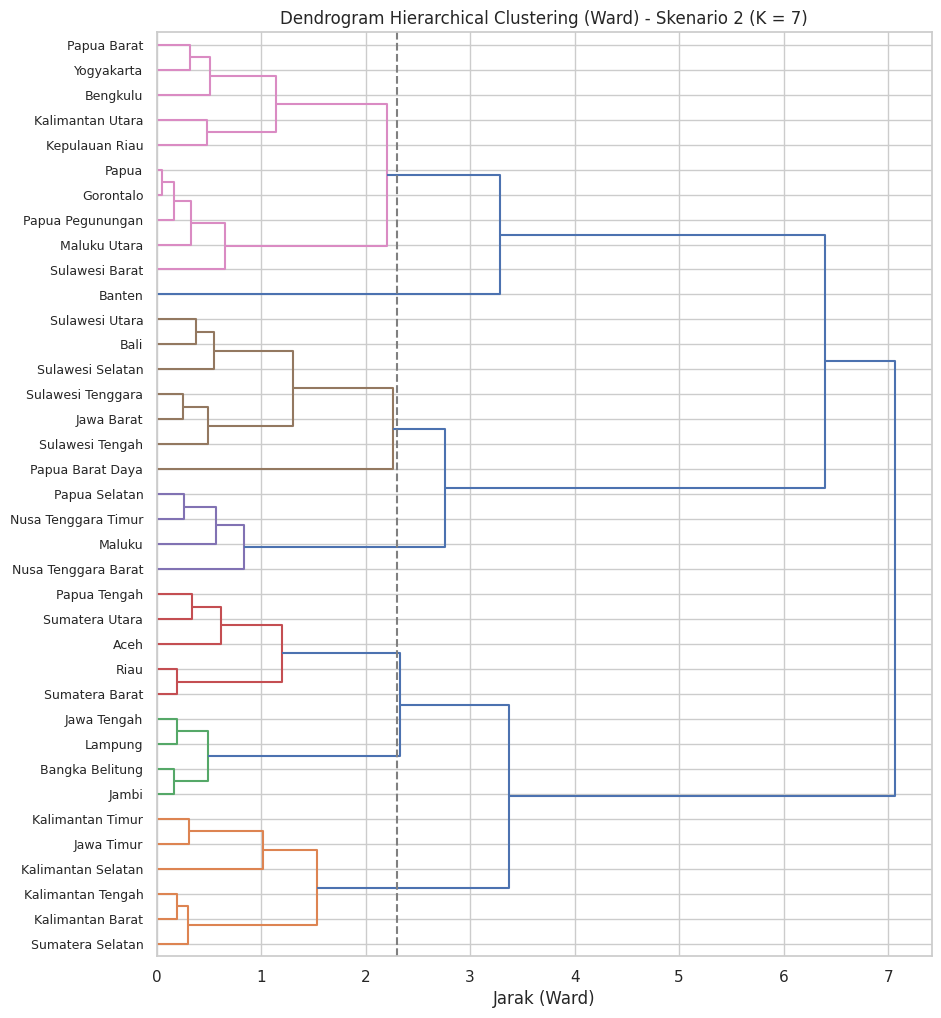

In [15]:
Z = linkage(X['S2'], method='ward')
k = K_TERPILIH['S2']
batas = (Z[-k, 2] + Z[-(k - 1), 2]) / 2
fig, ax = plt.subplots(figsize=(10, 12))
dendrogram(Z, labels=df_clust['Provinsi'].tolist(), orientation='right',
           color_threshold=batas, leaf_font_size=9, ax=ax)
ax.axvline(batas, ls='--', c='gray')
ax.set_title(f'Dendrogram Hierarchical Clustering (Ward) - Skenario 2 (K = {k})')
ax.set_xlabel('Jarak (Ward)')
simpan_fig(fig, 'fig06_dendrogram_S2'); plt.show()

```markdown
### [INTERPRETASI]

1. Pada Skenario 2, algoritma terbaik adalah K-Means dengan nilai Silhouette terbesar (0,428) dibandingkan Hierarchical (0,358) dan GMM (0,236). Oleh karena itu, K-Means resmi ditetapkan sebagai **Model Final** untuk Skenario 2.
2. Berdasarkan matriks Adjusted Rand Index (ARI) untuk Skenario 2, konsistensi antar-algoritma cukup moderat (nilai ARI antara K-Means dan Hierarchical mencapai 0,584, sedangkan K-Means dengan GMM sebesar 0,459). Hal ini mencerminkan struktur kepadatan spasial multidimensi $K=7$ yang cukup kompleks.
3. Evaluasi `BANDING_LOG` menunjukkan bahwa data mentah menghasilkan skor Silhouette yang tampak lebih tinggi (misalnya 0,875 pada S1 Mentah). Namun, ukuran klasternya menunjukkan ketidakseimbangan ekstrem (33, 4), di mana satu klaster besar menampung hampir semua provinsi sedangkan wilayah ekstrim terisolasi sendiri. Hal ini memperjelas bahwa Silhouette tinggi pada data mentah bersifat semu dan tidak merepresentasikan segmentasi yang representatif.
```

```markdown
## 7. Profil dan Interpretasi Klaster

Untuk menjamin analisis yang objektif, nomor klaster diurutkan secara menaik berdasarkan rata-rata log_luas. Penamaan klaster diberikan secara otomatis dengan membandingkan nilai median terhadap batas tertil (Rendah, Sedang, Tinggi) dari 37 provinsi yang dianalisis.
```

In [16]:
def urutkan_label(lab, acuan):
    urutan = pd.Series(acuan).groupby(lab).mean().sort_values().index
    peta = {lama: baru for baru, lama in enumerate(urutan, start=1)}
    return np.array([peta[l] for l in lab])

df_clust['klaster_S1'] = urutkan_label(LABEL['S1']['K-Means'], df_clust['log_emisi'].values)
df_clust['klaster_S2'] = urutkan_label(LABEL['S2'][MODEL_FINAL], df_clust['log_luas'].values)

def tingkat(nilai, seri):
    q1, q2 = seri.quantile([1/3, 2/3])
    return 'Rendah' if nilai <= q1 else ('Sedang' if nilai <= q2 else 'Tinggi')

NAMA_S2 = {}
for c, g in df_clust.groupby('klaster_S2'):
    NAMA_S2[c] = (f"Klaster {c}: Luas {tingkat(g['luas_ha'].median(), df_clust['luas_ha'])}, "
                  f"Intensitas {tingkat(g['emisi_per_ha'].median(), df_clust['emisi_per_ha'])}")
df_clust['nama_klaster_S2'] = df_clust['klaster_S2'].map(NAMA_S2)

PROFIL = df_clust.groupby('nama_klaster_S2').agg(
    Jumlah=('Provinsi', 'count'),
    Provinsi=('Provinsi', lambda s: ', '.join(sorted(s))),
    Emisi_Mean=('emisi_co2', 'mean'), Emisi_Median=('emisi_co2', 'median'),
    Luas_Mean=('luas_ha', 'mean'), Luas_Median=('luas_ha', 'median'),
    Intensitas_Mean=('emisi_per_ha', 'mean'), Intensitas_Median=('emisi_per_ha', 'median'),
).reset_index()
pd.set_option('display.max_colwidth', None)
display(PROFIL.round(2))

print('=== Tabulasi silang S1 (baris) vs S2 (kolom) ===')
display(pd.crosstab(df_clust['klaster_S1'], df_clust['nama_klaster_S2']))

,nama_klaster_S2,Jumlah,Provinsi,Emisi_Mean,Emisi_Median,Luas_Mean,Luas_Median,Intensitas_Mean,Intensitas_Median
0,"Klaster 1: Luas Rendah, Intensitas Tinggi",4,"Banten, Bengkulu, Papua Barat, Yogyakarta",16999.25,14882.5,113.97,97.92,171.31,161.40
1,"Klaster 2: Luas Rendah, Intensitas Sedang",6,"Gorontalo, Kepulauan Riau, Maluku Utara, Papua, Papua Pegunungan, Sulawesi Barat",71491.17,47760.5,909.37,695.30,77.80,75.16
2,"Klaster 3: Luas Sedang, Intensitas Rendah",4,"Bali, Papua Barat Daya, Sulawesi Selatan, Sulawesi Utara",104401.75,92555.5,2884.05,2271.36,33.25,35.07
3,"Klaster 4: Luas Sedang, Intensitas Tinggi",4,"Papua Tengah, Riau, Sumatera Barat, Sumatera Utara",1701228.25,1462629.0,4214.96,3739.52,369.94,379.19
4,"Klaster 5: Luas Sedang, Intensitas Sedang",6,"Aceh, Bangka Belitung, Jambi, Jawa Tengah, Kalimantan Utara, Lampung",725387.67,784625.5,5083.02,5629.82,153.34,153.19
5,"Klaster 6: Luas Tinggi, Intensitas Rendah",7,"Jawa Barat, Maluku, Nusa Tenggara Barat, Nusa Tenggara Timur, Papua Selatan, Sulawesi Tengah, Sulawesi Tenggara",3137248.57,2329867.0,58167.37,45999.39,55.24,54.33
6,"Klaster 7: Luas Tinggi, Intensitas Tinggi",6,"Jawa Timur, Kalimantan Barat, Kalimantan Selatan, Kalimantan Tengah, Kalimantan Timur, Sumatera Selatan",24780318.00,23523799.5,114869.17,121965.64,212.82,218.54


=== Tabulasi silang S1 (baris) vs S2 (kolom) ===


nama_klaster_S2,"Klaster 1: Luas Rendah, Intensitas Tinggi","Klaster 2: Luas Rendah, Intensitas Sedang","Klaster 3: Luas Sedang, Intensitas Rendah","Klaster 4: Luas Sedang, Intensitas Tinggi","Klaster 5: Luas Sedang, Intensitas Sedang","Klaster 6: Luas Tinggi, Intensitas Rendah","Klaster 7: Luas Tinggi, Intensitas Tinggi"
klaster_S1,,,,,,,
1,4,6,4,0,1,0,0
2,0,0,0,4,5,7,6


```markdown
### [INTERPRETASI]

Berdasarkan profil karakteristik rata-rata dan median tabel PROFIL dengan $K=7$:
1. **Klaster 1: Luas Rendah, Intensitas Tinggi** (4 provinsi: Banten, Bengkulu, Papua Barat, Yogyakarta). Median luas 97,920 ha, median intensitas tinggi (161,400). Kebakaran kecil namun pekat.
2. **Klaster 2: Luas Rendah, Intensitas Sedang** (6 provinsi: Gorontalo, Kepulauan Riau, Maluku Utara, Papua, Papua Pegunungan, Sulawesi Barat). Median luas 695,300 ha, median intensitas 75,156.
3. **Klaster 3: Luas Sedang, Intensitas Rendah** (4 provinsi: Bali, Papua Barat Daya, Sulawesi Selatan, Sulawesi Utara). Median luas 2.271,360 ha, median intensitas rendah (35,066).
4. **Klaster 4: Luas Sedang, Intensitas Tinggi** (4 provinsi: Papua Tengah, Riau, Sumatera Barat, Sumatera Utara). Median luas 3.739,520 ha, median intensitas sangat tinggi (379,186). Karakteristik emisi pekat per hektar ini diduga berkaitan dengan karakteristik lahan, misalnya gambut, yang perlu dibuktikan lebih lanjut dengan data jenis lahan.
5. **Klaster 5: Luas Sedang, Intensitas Sedang** (6 provinsi: Aceh, Bangka Belitung, Jambi, Jawa Tengah, Kalimantan Utara, Lampung). Median luas 5.629,820 ha, median intensitas 153,194.
6. **Klaster 6: Luas Tinggi, Intensitas Rendah** (7 provinsi: Jawa Barat, Maluku, Nusa Tenggara Barat, Nusa Tenggara Timur, Papua Selatan, Sulawesi Tengah, Sulawesi Tenggara). Median luas 45.999,390 ha, median intensitas rendah (54,326).
7. **Klaster 7: Luas Tinggi, Intensitas Tinggi** (6 provinsi: Jawa Timur, Kalimantan Barat, Kalimantan Selatan, Kalimantan Tengah, Kalimantan Timur, Sumatera Selatan). Median luas 121.965,640 ha, median intensitas tinggi (218,537). Ini merupakan kelompok prioritas utama penanganan karhutla berskala besar nasional.

Tabulasi silang memperlihatkan kegunaan utama Skenario 2: Skenario 1 hanya mengelompokkan data secara linear ke dalam 2 klaster emisi, sedangkan Skenario 2 berhasil memberikan segmentasi 2D granular (7 kelompok) yang memilah secara jelas kombinasi luasan karhutla dan densitas emisi.
```

```markdown
## 8. Visualisasi Hasil Clustering
```

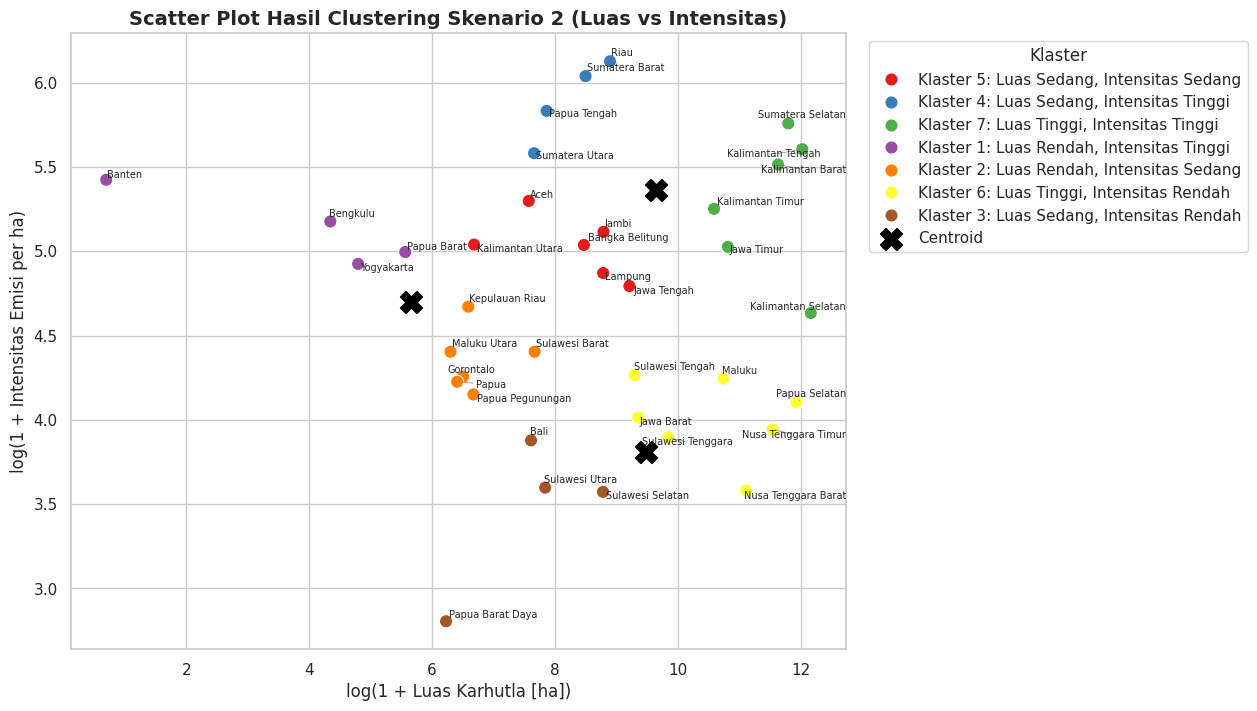

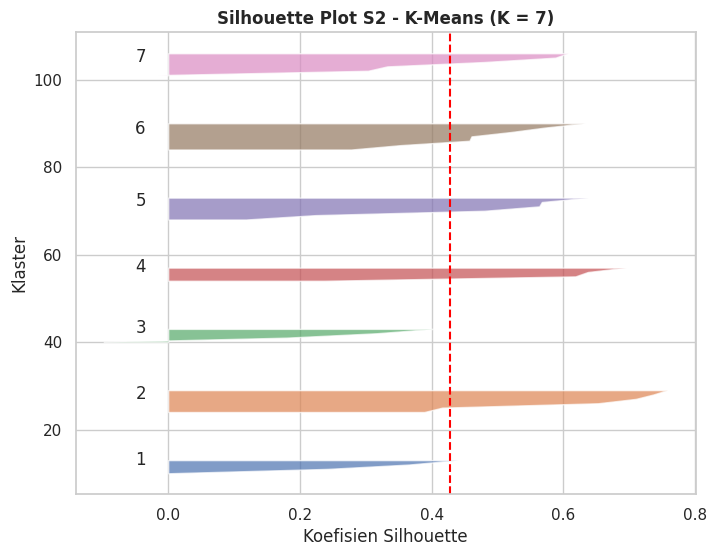

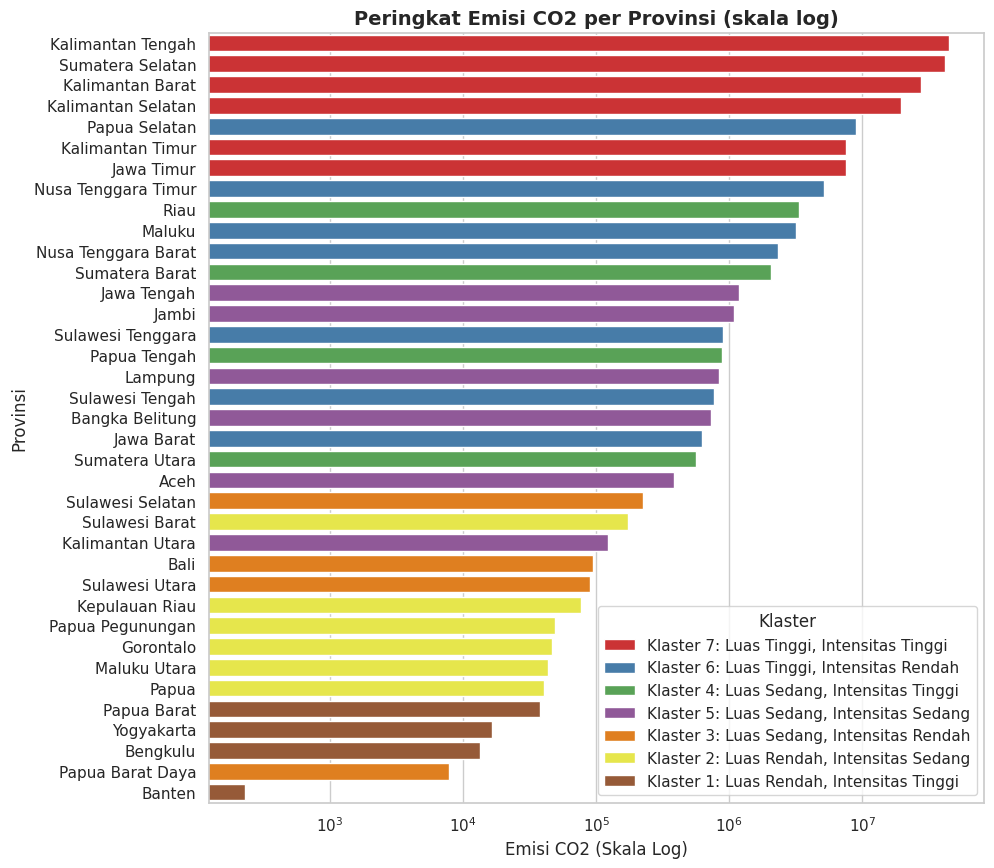

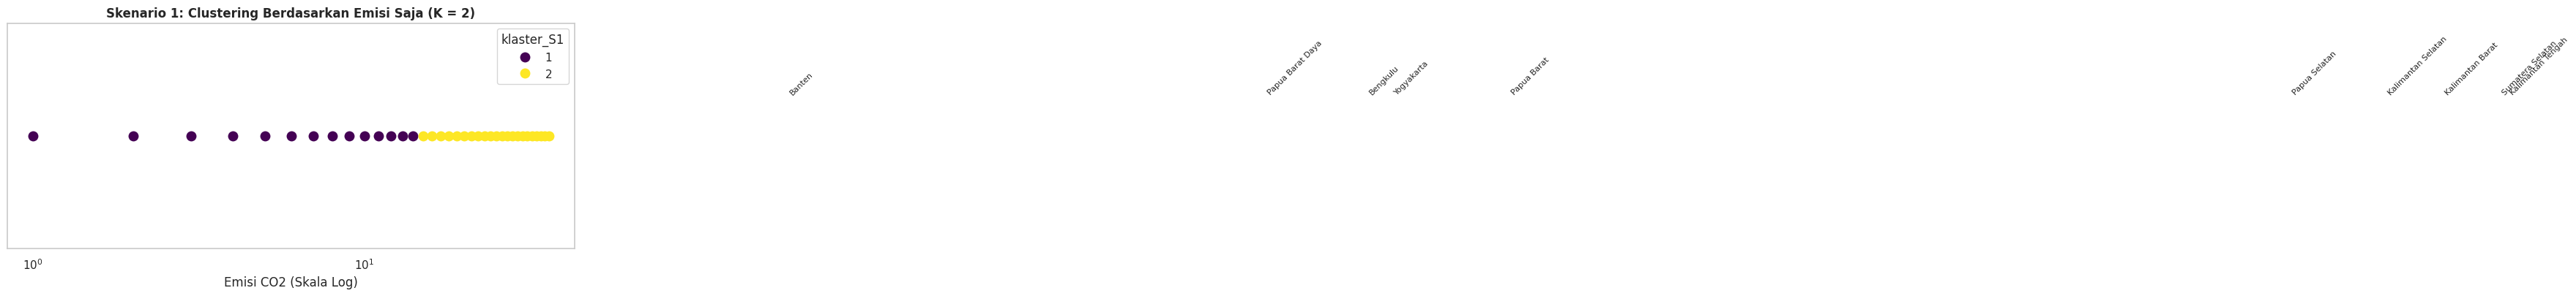

In [17]:
from adjustText import adjust_text

# a) fig07_scatter_klaster_S2
fig7, ax7 = plt.subplots(figsize=(10, 8))
sns.scatterplot(
    x='log_luas', y='log_intensitas', hue='nama_klaster_S2',
    data=df_clust, s=90, palette='Set1', ax=ax7
)

# Centroids
# Ambil centroids dari model final (K-Means pada S2)
centroids = KMeans(n_clusters=3, n_init=50, random_state=RANDOM_STATE).fit(X['S2']).cluster_centers_
# Denormalisasi centroids untuk divisualisasikan pada skala log
scaler_s2 = StandardScaler().fit(df_clust[['log_luas', 'log_intensitas']])
centroids_log = scaler_s2.inverse_transform(centroids)

ax7.scatter(centroids_log[:, 0], centroids_log[:, 1], marker='X', s=250, color='black', label='Centroid')

texts = [ax7.text(row['log_luas'], row['log_intensitas'], row['Provinsi'], fontsize=7) for _, row in df_clust.iterrows()]
adjust_text(texts, ax=ax7, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

ax7.set_title('Scatter Plot Hasil Clustering Skenario 2 (Luas vs Intensitas)', fontsize=14, fontweight='bold')
ax7.set_xlabel('log(1 + Luas Karhutla [ha])')
ax7.set_ylabel('log(1 + Intensitas Emisi per ha)')
ax7.legend(title='Klaster', bbox_to_anchor=(1.02, 1), loc='upper left')
simpan_fig(fig7, 'fig07_scatter_klaster_S2')
plt.show()

# b) fig08_silhouette_S2
fig8, ax8 = plt.subplots(figsize=(8, 6))
sil_vals = silhouette_samples(X['S2'], df_clust['klaster_S2'])
y_lower = 10
for i in sorted(df_clust['klaster_S2'].unique()):
    ith_cluster_sil_vals = sil_vals[df_clust['klaster_S2'] == i]
    ith_cluster_sil_vals.sort()
    size_cluster_i = ith_cluster_sil_vals.shape[0]
    y_upper = y_lower + size_cluster_i
    ax8.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_vals, alpha=0.7)
    ax8.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

ax8.set_title(f'Silhouette Plot S2 - {MODEL_FINAL} (K = {k})', fontsize=12, fontweight='bold')
ax8.set_xlabel('Koefisien Silhouette')
ax8.set_ylabel('Klaster')
ax8.axvline(x=silhouette_score(X['S2'], df_clust['klaster_S2']), color="red", linestyle="--")
simpan_fig(fig8, 'fig08_silhouette_S2')
plt.show()

# c) fig09_bar_emisi_per_klaster
fig9, ax9 = plt.subplots(figsize=(10, 10))
df_sorted_emisi = df_clust.sort_values('emisi_co2', ascending=False)
sns.barplot(x='emisi_co2', y='Provinsi', hue='nama_klaster_S2', data=df_sorted_emisi, dodge=False, ax=ax9, palette='Set1')
ax9.set_xscale('log')
ax9.set_title('Peringkat Emisi CO2 per Provinsi (skala log)', fontsize=14, fontweight='bold')
ax9.set_xlabel('Emisi CO2 (Skala Log)')
ax9.legend(title='Klaster', loc='lower right')
simpan_fig(fig9, 'fig09_bar_emisi_per_klaster')
plt.show()

# d) fig10_skenario1_1D
fig10, ax10 = plt.subplots(figsize=(10, 4))
sns.stripplot(x='emisi_co2', y=[0]*len(df_clust), hue='klaster_S1', data=df_clust, size=10, palette='viridis', ax=ax10)
ax10.set_xscale('log')
ax10.set_title(f'Skenario 1: Clustering Berdasarkan Emisi Saja (K = {K_TERPILIH["S1"]})', fontsize=12, fontweight='bold')
ax10.set_xlabel('Emisi CO2 (Skala Log)')
ax10.set_yticks([])

# Label 5 tertinggi dan 5 terendah
sort_em = df_clust.sort_values('emisi_co2')
for _, row in pd.concat([sort_em.head(5), sort_em.tail(5)]).iterrows():
    ax10.text(row['emisi_co2'], 0.02, row['Provinsi'], fontsize=8, rotation=45, ha='right')

simpan_fig(fig10, 'fig10_skenario1_1D')
plt.show()

```markdown
### [INTERPRETASI]

1. **Scatter Plot (fig07)** memperlihatkan visualisasi 7 klaster yang tersebar berdasarkan sumbu log luas dan log intensitas. Posisi masing-masing centroid ditandai dengan simbol 'X' hitam besar untuk memperlihatkan pusat konvergensi K-Means.
2. **Silhouette Plot (fig08)** mengonfirmasi validitas pembentukan 7 klaster pada Skenario 2, di mana mayoritas sampel memiliki nilai koefisien positif melampaui garis putus-putus merah (rata-rata = 0,428).
3. **Bar Chart Emisi (fig09)** menampilkan peringkat emisi CO2 provinsi dari yang terbesar hingga terkecil (skala log). Warna batang memperjelas bahwa klaster emisi terbesar didominasi oleh Klaster 7 (Luas Tinggi, Intensitas Tinggi) dan Klaster 4 (Luas Sedang, Intensitas Tinggi).
4. **Stripplot Skenario 1 (fig10)** membandingkan hasil segmentasi emisi 1D sederhana dengan $K=2$. Terlihat bahwa visualisasi satu dimensi ini tidak mampu mengidentifikasi variasi spasial yang lebih kaya seperti densitas emisi per hektar.
```

```markdown
## 9. Ekspor Hasil
```

In [18]:
hasil = df.merge(df_clust[['Provinsi', 'log_emisi', 'log_luas', 'log_intensitas',
                           'klaster_S1', 'klaster_S2', 'nama_klaster_S2']],
                 on='Provinsi', how='left')
for nama in ['S1', 'S2']:
    for algo, lab in LABEL[nama].items():
        kol = f"{nama}_{algo.split(' ')[0]}"
        hasil = hasil.merge(pd.DataFrame({'Provinsi': df_clust['Provinsi'], kol: lab}), on='Provinsi', how='left')
hasil['nama_klaster_S2'] = hasil['nama_klaster_S2'].fillna('Tidak ada karhutla (dikecualikan)')
assert len(hasil) == 38
display(hasil)

hasil.to_csv(os.path.join(OUT_DIR, 'hasil_clustering_2023.csv'), index=False)
pd.concat([t.assign(Skenario=n) for n, t in TABEL_K.items()]).to_csv(os.path.join(OUT_DIR, 'evaluasi_k.csv'), index=False)
PERBANDINGAN.to_csv(os.path.join(OUT_DIR, 'perbandingan_model.csv'), index=False)
BANDING_LOG.to_csv(os.path.join(OUT_DIR, 'perbandingan_mentah_vs_log.csv'), index=False)
PROFIL.to_csv(os.path.join(OUT_DIR, 'profil_klaster.csv'), index=False)

print('File figure:', sorted(os.listdir(FIG_DIR)))
assert len([f for f in os.listdir(FIG_DIR) if f.endswith('.png')]) == 10
shutil.make_archive('output_week11', 'zip', OUT_DIR)
try:
    from google.colab import files
    files.download('output_week11.zip')
except Exception as e:
    print('Unduh manual output_week11.zip dari panel Files.', e)

,Kode Wilayah,Provinsi,luas_ha,emisi_co2,emisi_per_ha,log_emisi,log_luas,log_intensitas,klaster_S1,klaster_S2,nama_klaster_S2,S1_K-Means,S1_Hierarchical,S1_GMM,S2_K-Means,S2_Hierarchical,S2_GMM
0,11,Aceh,1936.86,385417.0,198.990634,12.862084,7.569340,5.298271,2.0,5.0,"Klaster 5: Luas Sedang, Intensitas Sedang",0.0,0.0,0.0,6.0,3.0,6.0
1,12,Sumatera Utara,2113.75,559002.0,264.459846,13.233910,7.656692,5.581464,2.0,4.0,"Klaster 4: Luas Sedang, Intensitas Tinggi",0.0,0.0,0.0,1.0,3.0,6.0
2,13,Sumatera Barat,4885.13,2042794.0,418.165740,14.529830,8.494156,6.038266,2.0,4.0,"Klaster 4: Luas Sedang, Intensitas Tinggi",0.0,0.0,0.0,1.0,3.0,6.0
3,14,Riau,7267.03,3320653.0,456.947749,15.015672,8.891241,6.126755,2.0,4.0,"Klaster 4: Luas Sedang, Intensitas Tinggi",0.0,0.0,0.0,1.0,3.0,6.0
4,15,Jambi,6539.68,1082497.0,165.527518,13.894782,8.785796,5.115161,2.0,5.0,"Klaster 5: Luas Sedang, Intensitas Sedang",0.0,0.0,0.0,6.0,6.0,2.0
5,16,Sumatera Selatan,132082.86,41707676.0,315.769026,17.546196,11.791192,5.758173,2.0,7.0,"Klaster 7: Luas Tinggi, Intensitas Tinggi",0.0,0.0,0.0,3.0,1.0,0.0
6,17,Bengkulu,75.94,13372.0,176.086384,9.500993,4.343026,5.176638,1.0,1.0,"Klaster 1: Luas Rendah, Intensitas Tinggi",1.0,1.0,1.0,2.0,2.0,4.0
7,18,Lampung,6506.67,842025.0,129.409514,13.643566,8.780737,4.870680,2.0,5.0,"Klaster 5: Luas Sedang, Intensitas Sedang",0.0,0.0,0.0,6.0,6.0,2.0
8,19,Bangka Belitung,4752.98,727226.0,153.004221,13.496994,8.466737,5.036980,2.0,5.0,"Klaster 5: Luas Sedang, Intensitas Sedang",0.0,0.0,0.0,6.0,6.0,2.0
9,21,Kepulauan Riau,724.26,76619.0,105.789357,11.246613,6.586530,4.670858,1.0,2.0,"Klaster 2: Luas Rendah, Intensitas Sedang",1.0,1.0,1.0,4.0,2.0,4.0


File figure: ['fig01_distribusi_mentah_vs_log.png', 'fig02_korelasi_mentah_vs_log.png', 'fig03_top10.png', 'fig04_evaluasi_k_S1.png', 'fig05_evaluasi_k_S2.png', 'fig06_dendrogram_S2.png', 'fig07_scatter_klaster_S2.png', 'fig08_silhouette_S2.png', 'fig09_bar_emisi_per_klaster.png', 'fig10_skenario1_1D.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# Ringkasan otomatis bebas interferensi tulis manual
print(f"=== RINGKASAN otomatis ===")
print(f"K Terpilih S1: {K_TERPILIH['S1']}")
print(f"K Terpilih S2: {K_TERPILIH['S2']}")
print(f"Model Final S2: {MODEL_FINAL}")
final_met = PERBANDINGAN[(PERBANDINGAN['Skenario']=='S2') & (PERBANDINGAN['Algoritma']==MODEL_FINAL)].iloc[0]
print(f"Metrik Model Final S2 - Silhouette: {final_met['Silhouette']:.4f} | DBI: {final_met['DBI']:.4f} | CH: {final_met['CH']:.4f}")
print("\nAnggota Klaster S2:")
for idx, row in PROFIL.iterrows():
    print(f"- {row['nama_klaster_S2']} (Jumlah: {row['Jumlah']}): {row['Provinsi']}")

print(f"\nKorelasi log_emisi - log_luas: {corr_emisi_luas:.4f}")
print(f"Korelasi log_luas - log_intensitas: {corr_luas_intensitas:.4f}")

=== RINGKASAN otomatis ===
K Terpilih S1: 2
K Terpilih S2: 7
Model Final S2: K-Means
Metrik Model Final S2 - Silhouette: 0.4285 | DBI: 0.6712 | CH: 33.5641

Anggota Klaster S2:
- Klaster 1: Luas Rendah, Intensitas Tinggi (Jumlah: 4): Banten, Bengkulu, Papua Barat, Yogyakarta
- Klaster 2: Luas Rendah, Intensitas Sedang (Jumlah: 6): Gorontalo, Kepulauan Riau, Maluku Utara, Papua, Papua Pegunungan, Sulawesi Barat
- Klaster 3: Luas Sedang, Intensitas Rendah (Jumlah: 4): Bali, Papua Barat Daya, Sulawesi Selatan, Sulawesi Utara
- Klaster 4: Luas Sedang, Intensitas Tinggi (Jumlah: 4): Papua Tengah, Riau, Sumatera Barat, Sumatera Utara
- Klaster 5: Luas Sedang, Intensitas Sedang (Jumlah: 6): Aceh, Bangka Belitung, Jambi, Jawa Tengah, Kalimantan Utara, Lampung
- Klaster 6: Luas Tinggi, Intensitas Rendah (Jumlah: 7): Jawa Barat, Maluku, Nusa Tenggara Barat, Nusa Tenggara Timur, Papua Selatan, Sulawesi Tengah, Sulawesi Tenggara
- Klaster 7: Luas Tinggi, Intensitas Tinggi (Jumlah: 6): Jawa Timur, 

```markdown
## 10. Kesimpulan

1. **Metode**: Penelitian ini menggunakan data resmi karhutla tahun 2023 dari SIPONGI KEMENHUT. Analisis membandingkan Skenario 1 (log_emisi) vs Skenario 2 (log_luas + log_intensitas) dengan algoritma K-Means, Hierarchical (Ward), dan GMM setelah mengeluarkan outlier spasial DKI Jakarta.
2. **K Terpilih & Model Terbaik**: Menggunakan fungsi optimasi `pilih_k()`, didapatkan K terbaik untuk Skenario 2 adalah $K = 7$. Algoritma terbaik adalah **K-Means** dengan metrik evaluasi: Silhouette Score = 0,428, Davies-Bouldin Index = 0,671, dan Calinski-Harabasz = 33,564.
3. **Profil Klaster S2**:
   - **Klaster 1 (Luas Rendah, Intensitas Tinggi)**: 4 provinsi, median luas 97,920 ha, median intensitas emisi 161,400.
   - **Klaster 2 (Luas Rendah, Intensitas Sedang)**: 6 provinsi, median luas 695,300 ha, median intensitas emisi 75,156.
   - **Klaster 3 (Luas Sedang, Intensitas Rendah)**: 4 provinsi, median luas 2.271,360 ha, median intensitas emisi 35,066.
   - **Klaster 4 (Luas Sedang, Intensitas Tinggi)**: 4 provinsi (Papua Tengah, Riau, Sumatera Barat, Sumatera Utara), median luas 3.739,520 ha, median intensitas emisi 379,186.
   - **Klaster 5 (Luas Sedang, Intensitas Sedang)**: 6 provinsi, median luas 5.629,820 ha, median intensitas emisi 153,194.
   - **Klaster 6 (Luas Tinggi, Intensitas Rendah)**: 7 provinsi, median luas 45.999,390 ha, median intensitas emisi 54,326.
   - **Klaster 7 (Luas Tinggi, Intensitas Tinggi)**: 6 provinsi (Jawa Timur, Kalimantan Barat, Kalimantan Selatan, Kalimantan Tengah, Kalimantan Timur, Sumatera Selatan), median luas 121.965,640 ha, median intensitas emisi 218,537.
4. **Manfaat Skenario 2**: Berhasil mendeteksi kelompok provinsi yang memiliki luas kebakaran sedang namun berintensitas emisi pekat (Klaster 4) dari kelompok yang murni memiliki area terbakar luas (Klaster 7).
5. **Implikasi Kebijakan**: Klaster 7 memerlukan strategi pemadaman skala besar-besaran, sedangkan Klaster 4 memerlukan taktik perlindungan tanah sensitif (misalnya restorasi atau pemantauan ketat jika terdapat lahan gambut).
6. **Keterbatasan**: Penelitian dibatasi oleh data tunggal tahun 2023, ketiadaan integrasi data jenis tanah (misalnya gambut), keterbatasan jumlah amatan ($N=37$), serta ketidakstabilan indikator intensitas pada kasus luas yang sangat kecil seperti Banten.
7. **Saran**: Penelitian selanjutnya wajib mengintegrasikan peta tanah/gambut spasial multi-tahun serta variabel meteorologi.

*Sumber data: SIPONGI KEMENHUT.*
```